# Q3 · Steps 1–2 — Exploratory Data Analysis (Adult Income)

> **Run order for Question 3:** `01_EDA` → `02_Baseline_Model` → `03_AutoML_TPOT` (≈ 30–60 min!) → `04_Comparison_and_Save_Model` → `05_Deployment_Prep`
> then start the API and the Streamlit app (see `README.md`).

**Before running:** put the Adult Income csv (Kaggle `adult.csv` or UCI `adult.data`) into `data/q3_adult/`.
If the folder is empty the notebook tries to download the dataset from OpenML (needs internet).

In [1]:
# ---- Project setup: finds the project root automatically ----
import os, sys, json, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

def find_root():
    start = Path(os.environ.get("LAB_ROOT", Path.cwd())).resolve()
    for p in [start, *start.parents]:
        if (p / "requirements.txt").exists() and (p / "src").exists():
            return p
    raise RuntimeError("Project root not found. Open this notebook from inside the Prog_for_AI_Lab folder.")

ROOT = find_root()
sys.path.insert(0, str(ROOT / "src"))
print("Project root:", ROOT)

Project root: C:\Users\hp\Desktop\Prog_for_AI_Lab\Prog_for_AI_Lab


In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from lab_utils import save_json, load_json, savefig
import q3_common as q3
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. Load the dataset

In [3]:
df = q3.load_adult(ROOT / "data" / "q3_adult")
print("Source:", df.attrs.get("source"), "| shape:", df.shape)
display(df.head())
df.info()

Source: adult.csv | shape: (32561, 13)


,age,workclass,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,90,?,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,0
1,82,Private,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,0
2,66,?,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,0
3,54,Private,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,0
4,41,Private,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,0


<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       32561 non-null  str  
 2   education_num   32561 non-null  int64
 3   marital_status  32561 non-null  str  
 4   occupation      32561 non-null  str  
 5   relationship    32561 non-null  str  
 6   race            32561 non-null  str  
 7   sex             32561 non-null  str  
 8   capital_gain    32561 non-null  int64
 9   capital_loss    32561 non-null  int64
 10  hours_per_week  32561 non-null  int64
 11  native_country  32561 non-null  str  
 12  income          32561 non-null  int64
dtypes: int64(6), str(7)
memory usage: 5.3 MB


## 2. Data quality: missing values, duplicates, class balance

In [4]:
miss = df.isna().sum(); miss = miss[miss > 0]
print("Missing values ('?' in the original file):"); print(miss.to_string() if len(miss) else "none")
print("\nDuplicate rows:", int(df.duplicated().sum()))
bal = df[q3.TARGET].value_counts(normalize=True).rename({0: "<=50K", 1: ">50K"})
print("\nClass balance:"); print((bal * 100).round(2).to_string(), "%")

Missing values ('?' in the original file):
none

Duplicate rows: 3465

Class balance:
income
<=50K    75.92
>50K     24.08 %


## 3. Feature distributions

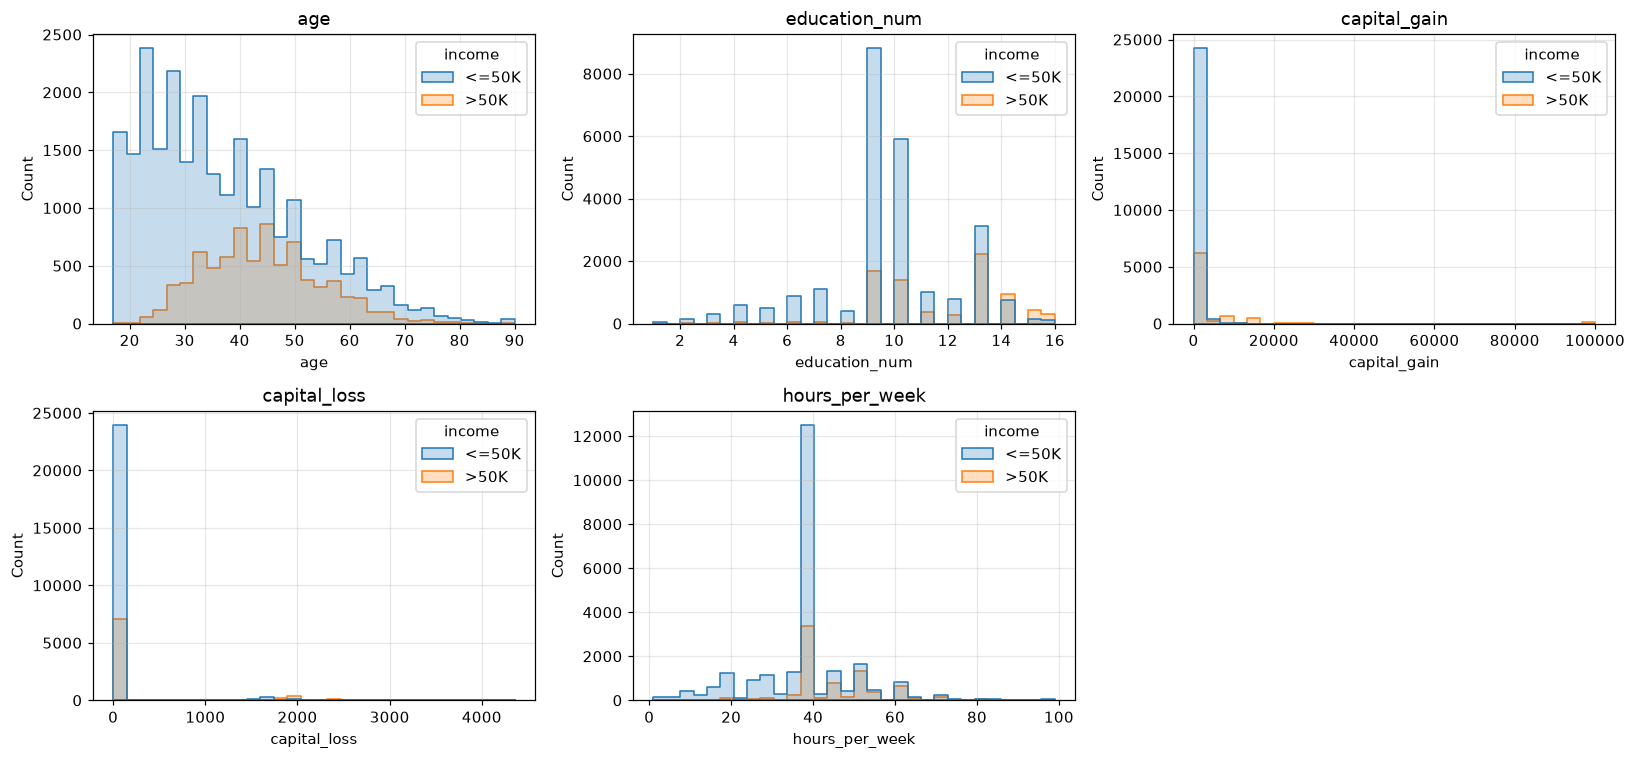

,count,mean,std,min,25%,50%,75%,max
age,32561.0,38.581647,13.640433,17.0,28.0,37.0,48.0,90.0
education_num,32561.0,10.080679,2.572720,1.0,9.0,10.0,12.0,16.0
capital_gain,32561.0,1077.648844,7385.292085,0.0,0.0,0.0,0.0,99999.0
capital_loss,32561.0,87.303830,402.960219,0.0,0.0,0.0,0.0,4356.0
hours_per_week,32561.0,40.437456,12.347429,1.0,40.0,40.0,45.0,99.0


In [5]:
num_cols = q3.RAW_NUMERIC
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(data=df, x=c, hue=df[q3.TARGET].map({0: "<=50K", 1: ">50K"}), bins=30, element="step", ax=ax)
    ax.set_title(c)
axes.ravel()[-1].axis("off")
plt.tight_layout(); savefig(fig, "q3", "eda_numeric"); plt.show()
display(df[num_cols].describe().T)

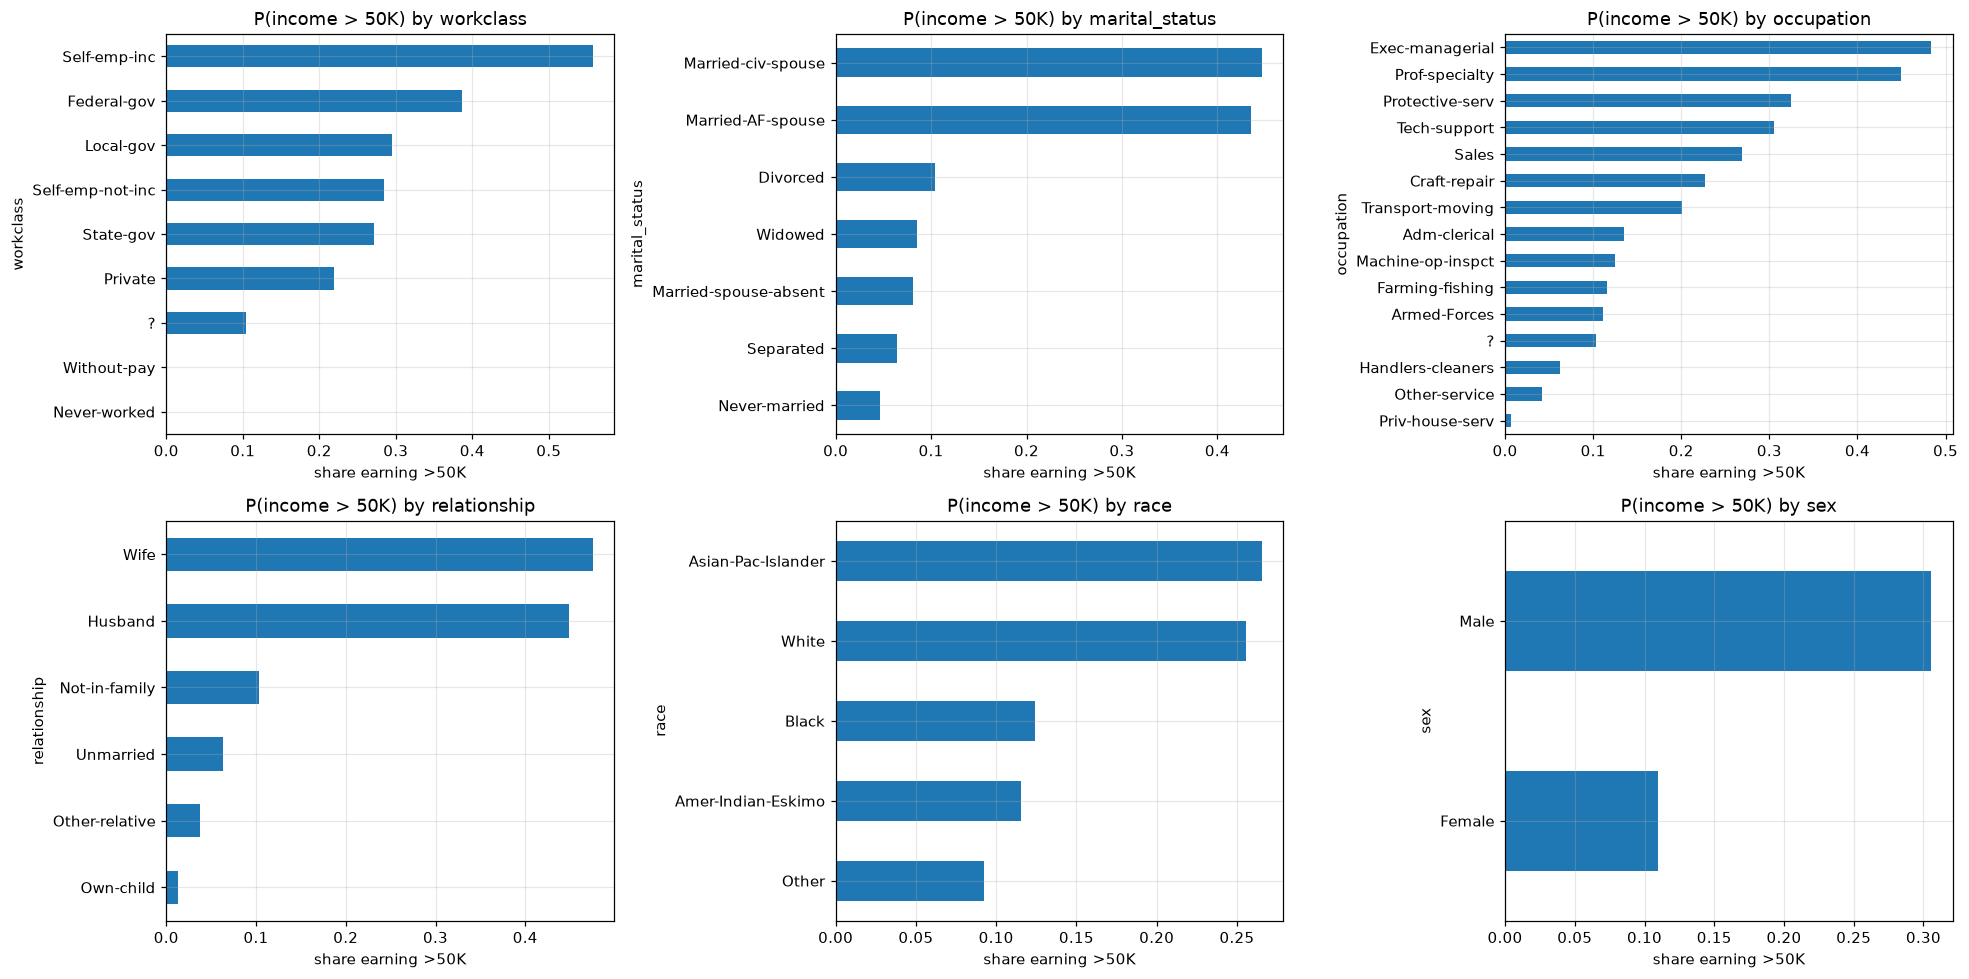

In [6]:
cats = ["workclass", "marital_status", "occupation", "relationship", "race", "sex"]
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, c in zip(axes.ravel(), cats):
    rate = df.groupby(c)[q3.TARGET].mean().sort_values()
    rate.plot.barh(ax=ax, color="tab:blue"); ax.set_title(f"P(income > 50K) by {c}"); ax.set_xlabel("share earning >50K")
plt.tight_layout(); savefig(fig, "q3", "eda_categorical"); plt.show()

## 4. Correlations

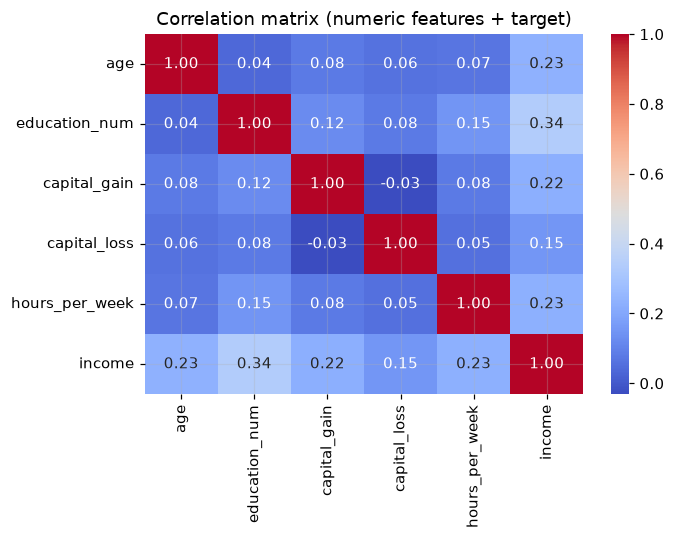

In [7]:
corr_df = df[num_cols + [q3.TARGET]].corr()
fig, ax = plt.subplots(figsize=(6.5, 5)); sns.heatmap(corr_df, annot=True, fmt=".2f", cmap="coolwarm", ax=ax)
ax.set_title("Correlation matrix (numeric features + target)"); plt.tight_layout(); savefig(fig, "q3", "eda_correlation"); plt.show()

## 5. Key insights (computed from the data)

In [ ]:
insights = []
insights.append(f"Class imbalance: only {bal['>50K']*100:.1f}% of people earn >50K, so accuracy alone is misleading; we also report F1 and ROC-AUC.")
c = corr_df[q3.TARGET].drop(q3.TARGET).sort_values(ascending=False)
insights.append(f"Numeric feature most correlated with high income: {c.index[0]} (r={c.iloc[0]:.2f}); next: {c.index[1]} (r={c.iloc[1]:.2f}).")
sx = df.groupby("sex")[q3.TARGET].mean()
insights.append(f"Share earning >50K by sex: " + ", ".join(f"{k}: {v*100:.1f}%" for k, v in sx.items()) + ".")
mar = df.assign(m=df.marital_status.astype(str).str.startswith("Married")).groupby("m")[q3.TARGET].mean()
insights.append(f"Married people earn >50K in {mar[True]*100:.1f}% of cases vs {mar[False]*100:.1f}% for others.")
edu = df.groupby(pd.cut(df.education_num, [0, 8, 10, 12, 16]))[q3.TARGET].mean()
insights.append("Income rises strongly with education years: " + ", ".join(f"{str(k)}: {v*100:.0f}%" for k, v in edu.items()) + ".")
insights.append(f"capital_gain/capital_loss are zero for {((df.capital_gain==0).mean()*100):.0f}% / {((df.capital_loss==0).mean()*100):.0f}% of people (very skewed) -> log / indicator features were engineered.")
if len(miss): insights.append("Missing values occur only in " + ", ".join(miss.index) + "; they are imputed with the most frequent value.")
for i in insights: print("•", i)
save_json({"rows": int(len(df)), "n_columns": int(df.shape[1]), "source": df.attrs.get("source"),
           "class_balance": {"<=50K": float(bal["<=50K"]), ">50K": float(bal[">50K"])},
           "missing": miss.to_dict(), "duplicates": int(df.duplicated().sum()), "insights": insights},
          ROOT / "results" / "q3" / "eda_summary.json")

• Class imbalance: only 24.1% of people earn >50K, so accuracy alone is misleading; we also report F1 and ROC-AUC.
• Numeric feature most correlated with high income: education_num (r=0.34); next: age (r=0.23).
• Share earning >50K by sex: Female: 10.9%, Male: 30.6%.
• Married people earn >50K in 43.7% of cases vs 6.4% for others.
• Income rises strongly with education years: (0, 8]: 6%, (8, 10]: 17%, (10, 12]: 26%, (12, 16]: 48%.
• capital_gain/capital_loss are zero for 92% / 95% of people (very skewed) -> log / indicator features were engineered.


: 

## 6. Preprocessing & feature-engineering plan (implemented in `src/q3_common.py`)
| Step | What | Why |
|---|---|---|
| Drop `fnlwgt`, `education` | census sampling weight is not a personal attribute; `education` duplicates `education_num` | avoids noise / redundancy |
| Missing values | numeric → median, categorical → most frequent | very few missing cells (`?`) |
| Scaling | `StandardScaler` on numeric | needed for Logistic Regression / distance-based models |
| Encoding | One-hot (unknown categories ignored) | models need numbers; API may receive unseen values |
| Derived features | `capital_net`, `log_capital_gain`, `has_capital_gain/loss`, `is_married`, `is_us`, `age_group`, `hours_category` | capture non-linear / skewed effects found in the EDA |
| Split | stratified 80/20, `random_state=42` | keeps class ratio identical in train and test |